# proSIM - SIM misuse detection: model training

Trains and evaluates two models on the synthetic CDR data (one row per SIM per day):

| Model | Type | Role |
|---|---|---|
| **Isolation Forest** | Unsupervised | Flags SIM-days with unusual usage, without using labels |
| **Random Forest** | Supervised (multiclass) | Classifies each SIM-day: `normal`, `unauthorized_sharing`, `data_reselling`, `ghost_usage`, `inactive_billing` |

Each section matches an issue in the **ML Training** milestone. Kernel: **proSIM (ml-service venv)**.

## 1. Setup and load data  (issue #1)

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn

SEED = 42
np.random.seed(SEED)

# Locate the ml-training folder whether the kernel starts in notebooks/ or elsewhere.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir() and p.name == "ml-training")
DATA_DIR = ROOT / "data"
REPORTS_DIR = ROOT / "reports"
MODELS_DIR = ROOT.parent / "ml-service" / "models"
REPORTS_DIR.mkdir(exist_ok=True)
MODELS_DIR.mkdir(exist_ok=True)

print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)
print("Data:", DATA_DIR)

scikit-learn 1.9.1 | pandas 3.1.0 | numpy 2.5.4
Data: C:\Users\user\Downloads\proSIM\ml-training\data


In [2]:
agg = pd.read_csv(DATA_DIR / "synthetic_cdr_daily_agg.csv")
labels = pd.read_csv(DATA_DIR / "synthetic_cdr_daily_labels.csv")

df = agg.merge(labels, on=["sim_id", "date"], how="left", validate="one_to_one")
assert df["label"].notna().all(), "every SIM-day must have a label"
df = df.sort_values(["sim_id", "date"]).reset_index(drop=True)

print(f"{len(df):,} SIM-days | {df.sim_id.nunique():,} SIMs | {df.date.min()} to {df.date.max()}")
df.head()

90,000 SIM-days | 1,000 SIMs | 2025-01-01 to 2025-03-31


,sim_id,date,total_download_mb,total_upload_mb,session_count,total_duration_s,hotspot_flag_count,geo_flag_count,roaming_sessions,unique_towers,...,offpeak_mb,max_session_mb,total_mb,billed_mb,tier,voice_minutes_used,sms_count,voice_minutes_remaining,sms_remaining,label
0,0,2025-01-01,365.86490,149.2379,10,1643,0,0,0,3,...,0.000000,170.04741,515.10280,515.103,professional,4.967,1,195.03,134,normal
1,0,2025-01-02,315.47680,148.7202,8,2627,0,0,0,3,...,0.000000,234.70801,464.19702,464.197,professional,4.033,1,191.00,133,normal
2,0,2025-01-03,338.00360,128.7998,11,3950,0,0,0,3,...,0.000000,127.63780,466.80340,466.803,professional,7.000,3,184.00,130,normal
3,0,2025-01-04,212.05319,61.7085,12,2060,0,0,0,2,...,11.541901,110.95750,273.76170,273.762,professional,1.783,4,182.22,126,normal
4,0,2025-01-05,134.54870,130.8992,9,2009,0,0,0,2,...,0.000000,142.36870,265.44790,265.448,professional,1.667,2,180.55,124,normal


In [3]:
# Columns and types, to plan feature engineering
df.dtypes.to_frame("dtype").T

,sim_id,date,total_download_mb,total_upload_mb,session_count,total_duration_s,hotspot_flag_count,geo_flag_count,roaming_sessions,unique_towers,...,offpeak_mb,max_session_mb,total_mb,billed_mb,tier,voice_minutes_used,sms_count,voice_minutes_remaining,sms_remaining,label
dtype,int64,str,float64,float64,int64,int64,int64,int64,int64,int64,...,float64,float64,float64,float64,str,float64,int64,float64,int64,str


## 2. Exploratory data analysis  (issue #2)

- [x] Label distribution table and chart (about 5% misuse)
- [x] Compare usage patterns of each misuse type against normal
- [x] Check and document that `billed_mb > total_mb` exactly separates inactive billing

Figures are saved to `reports/` for the write-up.

### 2.1 Data quality

In [4]:
# Class order and colours, reused by every chart in this notebook
CLASS_ORDER = ["normal", "unauthorized_sharing", "data_reselling", "ghost_usage", "inactive_billing"]
MISUSE = CLASS_ORDER[1:]
SHORT = {"normal": "normal", "unauthorized_sharing": "sharing", "data_reselling": "reselling",
         "ghost_usage": "ghost", "inactive_billing": "inactive\nbilling"}
CLASS_COLORS = {"normal": "#9a9893", "unauthorized_sharing": "#2a78d6", "data_reselling": "#eb6834",
                "ghost_usage": "#1baf7a", "inactive_billing": "#eda100"}

plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.edgecolor": "#b8b6b0", "axes.labelcolor": "#52514e", "axes.titlesize": 11,
    "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 10,
})

def savefig(fig, name):
    fig.savefig(REPORTS_DIR / name, dpi=150, bbox_inches="tight")

numeric = df.select_dtypes("number")
days_per_sim = df.groupby("sim_id").size()
negatives = (numeric < 0).sum()
print("Missing values:              ", int(df.isna().sum().sum()))
print("Duplicate (sim_id, date) rows:", int(df.duplicated(["sim_id", "date"]).sum()))
print("Days per SIM:                 ", days_per_sim.min(), "to", days_per_sim.max())
print("Columns with negative values: ", negatives[negatives > 0].to_dict() or "none")

Missing values:               0
Duplicate (sim_id, date) rows: 0
Days per SIM:                  90 to 90
Columns with negative values:  {'voice_minutes_remaining': 32}


### 2.2 Label distribution

In [5]:
counts = df["label"].value_counts().reindex(CLASS_ORDER)
sims_affected = df.groupby("label")["sim_id"].nunique().reindex(CLASS_ORDER)
dist = pd.DataFrame({
    "SIM-days": counts,
    "share of days (%)": (100 * counts / len(df)).round(2),
    "SIMs affected": sims_affected,
})
dist.loc["normal", "SIMs affected"] = np.nan  # every SIM has normal days

misuse_sims = df.loc[df.label != "normal", "sim_id"].nunique()
print(f"Misuse days: {(df.label != 'normal').mean():.2%} of all SIM-days")
print(f"SIMs with at least one misuse day: {misuse_sims} of {df.sim_id.nunique()}")
dist

Misuse days: 5.44% of all SIM-days
SIMs with at least one misuse day: 318 of 1000


,SIM-days,share of days (%),SIMs affected
label,,,
normal,85101,94.56,NaN
unauthorized_sharing,1958,2.18,120.0
data_reselling,752,0.84,85.0
ghost_usage,1397,1.55,85.0
inactive_billing,792,0.88,58.0


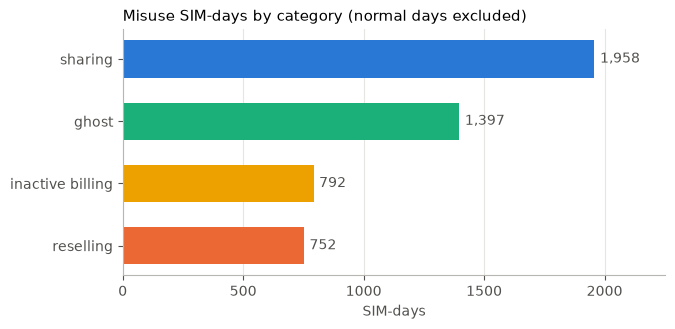

In [6]:
m = dist.loc[MISUSE, "SIM-days"].sort_values()
fig, ax = plt.subplots(figsize=(7, 3.2))
bars = ax.barh([SHORT[c].replace("\n", " ") for c in m.index], m.values, height=0.6,
               color=[CLASS_COLORS[c] for c in m.index])
ax.bar_label(bars, labels=[f"{v:,}" for v in m.values], padding=4, color="#52514e")
ax.set_xlabel("SIM-days")
ax.set_title("Misuse SIM-days by category (normal days excluded)", loc="left")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, m.max() * 1.15)
savefig(fig, "eda_label_distribution.png")
plt.show()

### 2.3 Misuse episodes
Each misuse is an *episode*: a run of consecutive days on one SIM.

In [7]:
episodes = pd.read_csv(DATA_DIR / "synthetic_cdr_labels.csv")
ep = episodes.groupby("category")["duration_days"].agg(
    episodes="count", median_days="median", min_days="min", max_days="max").reindex(MISUSE)
multi = episodes.groupby("sim_id").size()
print(f"{len(episodes)} episodes on {episodes.sim_id.nunique()} SIMs; "
      f"{(multi > 1).sum()} SIMs have more than one episode")
ep

355 episodes on 318 SIMs; 35 SIMs have more than one episode


,episodes,median_days,min_days,max_days
category,,,,
unauthorized_sharing,123,11.0,1,71
data_reselling,87,5.0,1,38
ghost_usage,86,10.5,1,72
inactive_billing,59,9.0,1,65


### 2.4 How each misuse type differs from normal usage
Medians per class. Shares are computed here only for exploration; they are built properly in section 3.

In [8]:
eda = df.copy()
eps = 1e-6
eda["upload_share"] = eda["total_upload_mb"] / (eda["total_mb"] + eps)
eda["offpeak_share"] = eda["offpeak_mb"] / (eda["total_mb"] + eps)
eda["mb_per_session"] = eda["total_mb"] / (eda["session_count"] + eps)
eda["billed_minus_used_mb"] = eda["billed_mb"] - eda["total_mb"]

COMPARE = ["total_mb", "total_upload_mb", "upload_share", "session_count", "mb_per_session",
           "max_session_mb", "hotspot_flag_count", "unique_towers", "geo_flag_count",
           "roaming_sessions", "apn_public_count", "offpeak_share", "voice_minutes_used",
           "sms_count", "billed_minus_used_mb"]
medians = eda.groupby("label")[COMPARE].median().reindex(CLASS_ORDER).T
medians.columns = [SHORT[c].replace("\n", " ") for c in medians.columns]
medians.round(2)

,normal,sharing,reselling,ghost,inactive billing
total_mb,393.32,1016.78,602.88,13.05,0.0
total_upload_mb,112.88,285.50,168.96,3.78,0.0
upload_share,0.29,0.30,0.30,0.29,0.0
session_count,10.00,10.00,10.00,6.00,5.0
mb_per_session,40.91,104.97,60.49,2.23,0.0
max_session_mb,180.96,453.24,284.27,6.22,0.0
hotspot_flag_count,0.00,2.00,0.00,0.00,0.0
unique_towers,3.00,3.00,3.00,2.00,2.0
geo_flag_count,0.00,0.00,0.00,0.00,0.0
roaming_sessions,0.00,0.00,0.00,0.00,0.0


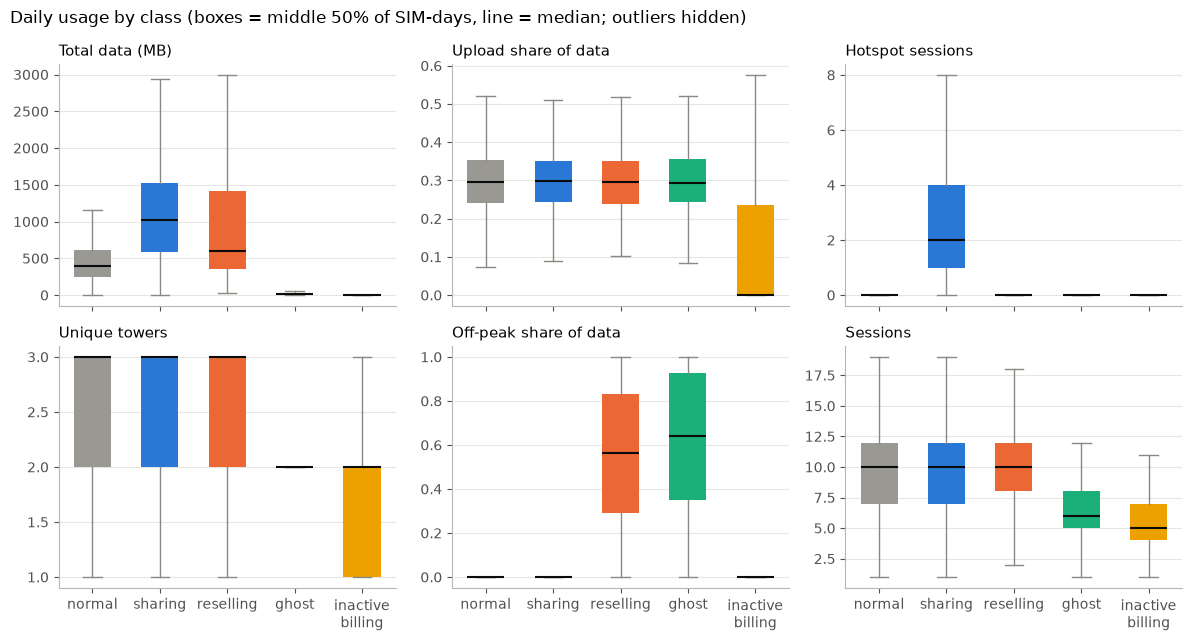

In [9]:
PANELS = [("total_mb", "Total data (MB)"), ("upload_share", "Upload share of data"),
          ("hotspot_flag_count", "Hotspot sessions"), ("unique_towers", "Unique towers"),
          ("offpeak_share", "Off-peak share of data"), ("session_count", "Sessions")]

fig, axes = plt.subplots(2, 3, figsize=(12, 6.5), sharex=True)
for ax, (col, title) in zip(axes.flat, PANELS):
    data = [eda.loc[eda.label == c, col].values for c in CLASS_ORDER]
    bp = ax.boxplot(data, widths=0.55, showfliers=False, patch_artist=True,
                    medianprops={"color": "#0b0b0b", "linewidth": 1.5},
                    whiskerprops={"color": "#8a8883"}, capprops={"color": "#8a8883"},
                    boxprops={"linewidth": 0})
    for patch, c in zip(bp["boxes"], CLASS_ORDER):
        patch.set_facecolor(CLASS_COLORS[c])
    ax.set_title(title, loc="left")
    ax.grid(axis="x", visible=False)
for ax in axes[-1]:
    ax.set_xticks(range(1, len(CLASS_ORDER) + 1), [SHORT[c] for c in CLASS_ORDER])
fig.suptitle("Daily usage by class (boxes = middle 50% of SIM-days, line = median; outliers hidden)",
             x=0.01, ha="left", fontsize=12)
fig.tight_layout()
savefig(fig, "eda_usage_by_class.png")
plt.show()

### 2.5 Misuse as a change in a SIM's own behaviour
One example SIM per misuse type: daily data use, with the misuse episode shaded. Comparing a day with the same SIM's recent past is the idea behind the baseline features in section 3.

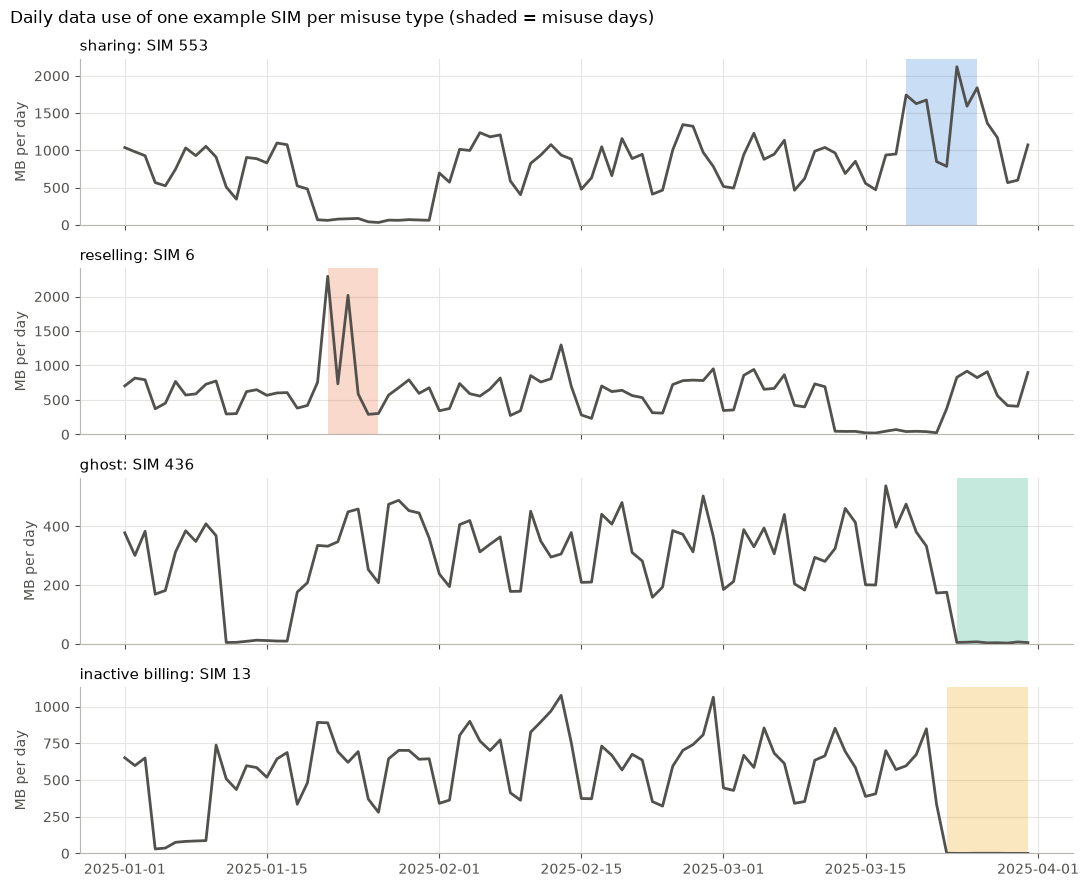

In [10]:
def pick_example(category):
    """A SIM whose episode of this type starts after day 20 (so there is history before it)."""
    cand = episodes[(episodes.category == category) & (episodes.start_day >= 20)].copy()
    cand["gap"] = (cand.duration_days - cand.duration_days.median()).abs()
    return int(cand.sort_values(["gap", "sim_id"]).iloc[0].sim_id)

fig, axes = plt.subplots(len(MISUSE), 1, figsize=(11, 9), sharex=True)
for ax, cat in zip(axes, MISUSE):
    sim = pick_example(cat)
    s = df[df.sim_id == sim].copy()
    s["date"] = pd.to_datetime(s["date"])
    ax.plot(s["date"], s["total_mb"], color="#52514e", linewidth=2)
    in_ep = s["label"] == cat
    ax.fill_between(s["date"], 0, 1, where=in_ep, transform=ax.get_xaxis_transform(),
                    color=CLASS_COLORS[cat], alpha=0.25, step="mid", linewidth=0)
    ax.set_title(f"{SHORT[cat].replace(chr(10), ' ')}: SIM {sim}", loc="left")
    ax.set_ylabel("MB per day")
    ax.set_ylim(bottom=0)
fig.suptitle("Daily data use of one example SIM per misuse type (shaded = misuse days)",
             x=0.01, ha="left", fontsize=12)
fig.tight_layout()
savefig(fig, "eda_example_timeseries.png")
plt.show()

### 2.6 Is inactive billing trivially separable?
If one simple rule finds every inactive-billing day, high model scores on that class reflect how the data was generated, not model skill.

In [11]:
gap = df["billed_mb"] - df["total_mb"]
rule = gap > 1  # billed more than 1 MB above what was actually used
is_ib = df["label"] == "inactive_billing"
print(pd.crosstab(rule.rename("billed > used + 1 MB"), is_ib.rename("label is inactive_billing")))
print()
print("Billed minus used, by class (MB):")
gap.groupby(df["label"]).describe()[["min", "50%", "max"]].reindex(CLASS_ORDER).round(3)

label is inactive_billing  False  True 
billed > used + 1 MB                   
False                      89208      0
True                           0    792

Billed minus used, by class (MB):


,min,50%,max
label,,,
normal,-0.001,0.0,0.001
unauthorized_sharing,-0.001,0.0,0.001
data_reselling,-0.001,0.0,0.001
ghost_usage,-0.001,0.0,0.001
inactive_billing,998.072,2000.0,3000.000


### 2.7 Misuse by subscriber tier

In [12]:
tier_tab = (pd.crosstab(df["tier"], df["label"], normalize="index") * 100).reindex(columns=CLASS_ORDER)
tier_tab.columns = [SHORT[c].replace("\n", " ") for c in tier_tab.columns]
tier_tab.insert(0, "SIM-days", df["tier"].value_counts())
tier_tab.round(2)

,SIM-days,normal,sharing,reselling,ghost,inactive billing
tier,,,,,,
manager,29610,95.20,1.74,0.90,1.29,0.87
professional,46890,94.43,2.25,0.88,1.59,0.86
support,13500,93.59,2.88,0.53,2.00,0.99


### 2.8 Quiet periods vs ghost usage
Some normal periods also have very low data use (e.g. a SIM owner on leave). Which features tell them apart from ghost usage?

In [13]:
low = eda["total_mb"] < 50
print("Days with under 50 MB, by class:")
print(eda.loc[low, "label"].value_counts().reindex(CLASS_ORDER).fillna(0).astype(int).to_string())
print(f"Quiet normal days are spread over {eda.loc[low & (eda.label == 'normal'), 'sim_id'].nunique()} SIMs")

QUIET = ["total_mb", "session_count", "unique_towers", "offpeak_share", "voice_minutes_used", "sms_count"]
quiet_vs_ghost = (eda[low & eda.label.isin(["normal", "ghost_usage"])]
                  .groupby("label")[QUIET].median()
                  .rename(index={"normal": "quiet normal days", "ghost_usage": "ghost usage days"}))
quiet_vs_ghost.round(2)

Days with under 50 MB, by class:
label
normal                  1310
unauthorized_sharing      27
data_reselling             4
ghost_usage             1310
inactive_billing         792
Quiet normal days are spread over 199 SIMs


,total_mb,session_count,unique_towers,offpeak_share,voice_minutes_used,sms_count
label,,,,,,
ghost usage days,12.02,6.0,2.0,0.63,0.17,0.0
quiet normal days,10.48,6.0,2.0,0.00,0.00,0.0


### 2.9 Findings

**Data quality.** No missing values or duplicate rows, and every SIM has all 90 days. `voice_minutes_remaining` goes negative on 32 days (lowest −21 minutes), most likely use beyond the bundle; it is left as is.

**Imbalance.** 5.44% of SIM-days are misuse, and 318 of 1,000 SIMs have at least one misuse episode. This calls for class weights in the Random Forest and for precision, recall and PR-AUC rather than accuracy, which would be 94.6% for a model that predicts "normal" every time.

**Episodes are short.** Median length runs from 5 days (data reselling) to 11 days (unauthorized sharing); some last a single day. 35 SIMs have more than one episode.

**Each misuse type has its own signature:**

| Type | What changes compared with normal days |
|---|---|
| Unauthorized sharing | About 2.6× the data (median 1,017 vs 393 MB) and hotspot sessions (median 2 vs 0) |
| Data reselling | More data (median 603 MB), over half of it off-peak (median share 0.56 vs 0). Upload share is the same as normal (0.30 vs 0.29), so upload share alone does not reveal reselling |
| Ghost usage | Almost no data (median 13 MB), fewer sessions (6 vs 10) and towers (2 vs 3), no SMS, and most of that little data off-peak (0.64) |
| Inactive billing | No data, voice or SMS, yet 1,000–3,000 MB billed |

**Inactive billing is perfectly separable.** Billed MB exceeds used MB by more than 1 MB on all 792 inactive-billing days and on no other day; for every other class the gap is within ±0.001 MB. Near-perfect model scores on this class will reflect how the data was generated, which should be stated in the write-up.

**Quiet periods are not misuse.** 1,310 normal days on 199 SIMs have under 50 MB, the same number of days as ghost usage. They match ghost usage on volume, sessions, towers, voice and SMS; only the off-peak share separates them (0.00 vs 0.63). Low usage on its own must therefore not be treated as suspicious.

**Tier matters little.** Misuse affects 4.8% of manager days, 5.6% of professional and 6.4% of support days, mostly through more sharing on support lines. Tier is kept as a feature but is expected to be weak.

**What this means for feature engineering (section 3):**
- Compare each day with the SIM's own recent past, since sharing and reselling are increases on top of very different normal levels.
- Include off-peak share (separates reselling, and separates ghost usage from quiet periods) and hotspot share (sharing).
- Include the billing gap (inactive billing).
- Split train and test by SIM, so episodes on the same SIM never appear on both sides.


## 3. Feature engineering  (issue #3)

- [x] Raw daily usage features
- [x] Usage-pattern ratios: upload share, off-peak share, hotspot share, public-APN share, MB per session
- [x] Billing gap: `billed_mb - total_mb`, billed / used
- [x] Per-SIM 14-day baseline using PAST days only (`shift(1)` before the rolling window): ratio to median, z-score
- [x] One-hot encode `tier`; never use `label`, `sim_id` or `date` as features

Every feature for a day uses only that day and the days before it, so the same code can score live data later.

### 3.1 Build the features

In [14]:
# Raw daily usage columns used as features.
# Not used: voice_minutes_remaining / sms_remaining (running bundle balances that depend on the
# billing cycle, not on behaviour) and label / sim_id / date (identifiers and the target).
RAW_COLS = [
    "total_download_mb", "total_upload_mb", "total_mb", "session_count", "data_session_count",
    "total_duration_s", "max_session_mb", "hotspot_flag_count", "geo_flag_count", "roaming_sessions",
    "unique_towers", "apn_public_count", "offpeak_session_count", "offpeak_mb", "billed_mb",
    "voice_minutes_used", "sms_count",
]
# Columns compared with each SIM's own recent past
BASELINE_COLS = ["total_mb", "total_upload_mb", "session_count", "unique_towers",
                 "hotspot_flag_count", "offpeak_mb", "billed_mb"]
TIERS = ["professional", "manager", "support"]
BASELINE_WINDOW = 14  # days of history
MIN_HISTORY = 3       # days needed before a baseline is used
EPS = 1e-6


def build_features(data: pd.DataFrame) -> pd.DataFrame:
    """One feature row per SIM-day, in the same row order as `data`."""
    d = data.copy()
    d["date"] = pd.to_datetime(d["date"])
    d = d.sort_values(["sim_id", "date"])
    out = pd.DataFrame(index=d.index)

    # 1. Raw daily usage
    for c in RAW_COLS:
        out[c] = d[c].astype(float)

    # 2. Usage-pattern ratios: HOW the line is used, independent of volume
    out["upload_share"] = d["total_upload_mb"] / (d["total_mb"] + EPS)
    out["offpeak_share"] = d["offpeak_mb"] / (d["total_mb"] + EPS)
    out["hotspot_share"] = d["hotspot_flag_count"] / (d["session_count"] + EPS)
    out["public_apn_share"] = d["apn_public_count"] / (d["data_session_count"] + EPS)
    out["mb_per_session"] = d["total_mb"] / (d["session_count"] + EPS)

    # 3. Billing vs actual usage
    out["billed_minus_used_mb"] = d["billed_mb"] - d["total_mb"]
    out["billed_to_used_ratio"] = d["billed_mb"] / (d["total_mb"] + 1.0)

    # 4. Change against the SIM's own past (shift(1): today is never part of its own baseline)
    #    - 14-day baseline: catches sudden changes, but absorbs an episode after ~2 weeks (see 3.4)
    #    - long-term baseline (median of ALL earlier days): keeps long episodes visible
    by_sim = d.groupby("sim_id")
    for c in BASELINE_COLS:
        past = by_sim[c].shift(1)
        window = past.groupby(d["sim_id"]).rolling(BASELINE_WINDOW, min_periods=MIN_HISTORY)
        med = window.median().reset_index(level=0, drop=True)
        std = window.std().reset_index(level=0, drop=True)
        out[f"{c}_vs_baseline"] = (d[c] / (med + 1.0)).fillna(1.0)   # no history yet -> neutral 1
        out[f"{c}_z"] = ((d[c] - med) / (std + 1.0)).fillna(0.0)      # no history yet -> neutral 0
        lt_med = (past.groupby(d["sim_id"]).expanding(min_periods=MIN_HISTORY).median()
                  .reset_index(level=0, drop=True))
        out[f"{c}_vs_longterm"] = (d[c] / (lt_med + 1.0)).fillna(1.0)

    # 5. Subscriber tier, one-hot
    for t in TIERS:
        out[f"tier_{t}"] = (d["tier"] == t).astype(int)

    out = out.replace([np.inf, -np.inf], 0.0).fillna(0.0)
    return out.loc[data.index]


X = build_features(df)
y = df["label"].to_numpy()
y_bin = (y != "normal").astype(int)  # 1 = any misuse, for misuse-vs-normal metrics
FEATURES = list(X.columns)

groups = {
    "raw daily usage": RAW_COLS,
    "usage-pattern ratios": ["upload_share", "offpeak_share", "hotspot_share", "public_apn_share", "mb_per_session"],
    "billing gap": ["billed_minus_used_mb", "billed_to_used_ratio"],
    "change vs own 14-day baseline": [f for f in FEATURES if f.endswith(("_vs_baseline", "_z"))],
    "change vs own long-term baseline": [f for f in FEATURES if f.endswith("_vs_longterm")],
    "tier": [f"tier_{t}" for t in TIERS],
}
assert sum(len(v) for v in groups.values()) == len(FEATURES)
print(f"Feature matrix: {X.shape[0]:,} rows x {X.shape[1]} features")
pd.DataFrame({"features": [len(v) for v in groups.values()]}, index=groups.keys())

Feature matrix: 90,000 rows x 48 features


,features
raw daily usage,17
usage-pattern ratios,5
billing gap,2
change vs own 14-day baseline,14
change vs own long-term baseline,7
tier,3


### 3.2 Checks: no gaps, no look-ahead

In [15]:
assert np.isfinite(X.to_numpy()).all(), "features contain NaN or inf"
assert not {"label", "sim_id", "date"} & set(FEATURES), "identifier or target used as a feature"

no_history = (df.groupby("sim_id").cumcount() < MIN_HISTORY).sum()
print(f"Rows without a baseline yet (first {MIN_HISTORY} days of each SIM): {no_history:,} "
      f"-> neutral values (ratio 1, z-score 0)")

# Look-ahead test: rebuild features using only data up to the end of February.
# If any feature used future days, the January-February rows would come out different.
cutoff = "2025-02-28"
early = df[df["date"] <= cutoff]
X_early = build_features(early)
diff = (X_early - X.loc[early.index]).abs().to_numpy().max()
print(f"Largest difference after removing all March data: {diff:.2e}")
assert diff < 1e-9, "features use future days"
print("OK: every feature uses only the current day and earlier days")

Rows without a baseline yet (first 3 days of each SIM): 3,000 -> neutral values (ratio 1, z-score 0)


Largest difference after removing all March data: 0.00e+00
OK: every feature uses only the current day and earlier days


### 3.3 Do the engineered features separate the classes?
Medians per class of the features the EDA pointed to.

In [16]:
KEY = ["total_mb_vs_baseline", "total_mb_vs_longterm", "total_mb_z", "hotspot_share", "offpeak_share",
       "session_count_vs_baseline", "unique_towers_vs_baseline", "billed_minus_used_mb"]
key_medians = X[KEY].groupby(df["label"]).median().reindex(CLASS_ORDER).T
key_medians.columns = [SHORT[c].replace("\n", " ") for c in key_medians.columns]
key_medians.round(2)

,normal,sharing,reselling,ghost,inactive billing
total_mb_vs_baseline,0.99,1.21,1.10,0.68,0.00
total_mb_vs_longterm,1.00,1.89,1.11,0.09,0.00
total_mb_z,-0.01,0.55,0.11,-0.35,-0.02
hotspot_share,0.00,0.24,0.00,0.00,0.00
offpeak_share,0.00,0.00,0.56,0.64,0.00
session_count_vs_baseline,0.92,0.91,0.92,0.74,0.67
unique_towers_vs_baseline,0.75,0.75,0.75,0.67,0.57
billed_minus_used_mb,0.00,0.00,0.00,0.00,2000.00


### 3.4 Does the baseline absorb long episodes?
The 14-day baseline is the median of the previous 14 days. Once an episode has run for a week or more, that window fills with misuse days and the misuse starts to look normal. The long-term baseline uses all earlier days, so it drifts far more slowly. Both are kept: one catches sudden changes, the other long episodes.

In [17]:
# Day number within each run of the same label on a SIM (1 = first day of the run)
run_id = (df["label"] != df.groupby("sim_id")["label"].shift()).cumsum()
day_in_run = df.groupby(run_id).cumcount() + 1
stage = pd.cut(day_in_run, [0, 3, 7, 14, 1000], labels=["days 1-3", "days 4-7", "days 8-14", "day 15+"])
misuse = df.label != "normal"
LONG_TYPES = ["unauthorized_sharing", "data_reselling", "ghost_usage"]

for col, name in [("total_mb_vs_baseline", "14-day baseline"), ("total_mb_vs_longterm", "long-term baseline")]:
    drift = (X.loc[misuse, col].groupby([df["label"], stage], observed=True).median()
             .unstack().reindex(LONG_TYPES))
    print(f"Data used vs {name}, median by days into the episode (normal days: ~1)")
    display(drift.round(2))

print("Number of misuse days in each stage:")
df.loc[misuse].groupby(["label", stage], observed=True).size().unstack().reindex(LONG_TYPES)

Data used vs 14-day baseline, median by days into the episode (normal days: ~1)


,days 1-3,days 4-7,days 8-14,day 15+
label,,,,
unauthorized_sharing,2.27,2.07,1.24,0.98
data_reselling,1.23,1.14,1.02,1.00
ghost_usage,0.04,0.06,0.76,0.92


Data used vs long-term baseline, median by days into the episode (normal days: ~1)


,days 1-3,days 4-7,days 8-14,day 15+
label,,,,
unauthorized_sharing,2.28,2.18,2.01,1.57
data_reselling,1.18,1.13,1.10,1.03
ghost_usage,0.03,0.04,0.07,0.56


Number of misuse days in each stage:


,days 1-3,days 4-7,days 8-14,day 15+
label,,,,
unauthorized_sharing,340,337,435,846
data_reselling,233,189,176,154
ghost_usage,248,260,291,598


### 3.5 Findings

**48 features in five groups:** 17 raw daily usage columns, 5 usage-pattern ratios, 2 billing-gap features, 21 comparisons with the SIM's own past (14-day and long-term), and 3 tier columns. `voice_minutes_remaining` and `sms_remaining` are left out: they are running bundle balances that depend on the billing cycle, not on behaviour.

**No look-ahead.** Every feature for a day uses only that day and earlier days. This was tested, not assumed: rebuilding the features without any March data leaves every January and February value unchanged. The same code can therefore score live data, one day at a time. The first 3 days of each SIM (3,000 rows) have no history yet and get neutral baseline values.

**The features separate the classes the way the EDA suggested** (medians, section 3.3):
- Sharing: 1.89× the SIM's long-term usage, and about a quarter of sessions on hotspot (0.24 vs 0).
- Reselling: over half of data off-peak (0.56 vs 0); its volume change is small (1.11×), so reselling relies on the off-peak share.
- Ghost usage: 0.09× the SIM's long-term usage, with most of that off-peak (0.64).
- Inactive billing: about 2,000 MB billed above what was used; every other class sits at 0.

**A 14-day baseline alone absorbs long episodes.** After about two weeks the window is full of misuse days, so the misuse starts to look normal: sharing drops from 2.27× its baseline in the first 3 days to 0.98× after day 15, and ghost usage rises from 0.04× to 0.92×. This matters because 43% of sharing days and 43% of ghost-usage days fall after day 15. The long-term baseline (median of all earlier days) drifts far more slowly: sharing is still 2.01× at days 8–14 and 1.57× after day 15, and ghost usage stays at 0.07× through day 14. Both baselines are kept, because the 14-day one reacts faster to sudden changes.

**Limitations for the write-up:**
- Reselling looks only slightly different in volume (1.03–1.18× its baseline), so its detection depends mostly on off-peak share. Session-level features may help if it scores poorly.
- Very long episodes (beyond about a month) will still slowly pull the long-term baseline towards the misuse level.


## 4. Train/test split by SIM  (issue #4)

- [x] Split by SIM: every SIM's 90 days go entirely to train or entirely to test
- [x] Assert no SIM is in both sets; report the misuse share of each

**Why by SIM:** a random split of rows would put days 1–60 of a SIM in training and days 61–90 of the same SIM in
testing. The model would then be tested on subscribers it already knows, which inflates the scores. Splitting by SIM
tests it on subscribers it has never seen, as it will be in production.

**Why stratified:** only 318 SIMs have any misuse, and `inactive_billing` occurs on just 58 of them. A purely random
group split (`GroupShuffleSplit`) can leave the test set with noticeably more or fewer of a rare type by chance.
`StratifiedGroupKFold` still keeps every SIM whole, but picks the groups so each class keeps a similar share on both
sides. One fold of four = a 75% / 25% split.

**Is it safe that features were built before splitting?** Yes. Every feature is computed from one SIM's own history
(section 3), with no statistic fitted across SIMs (no scaling, no global averages), so nothing from test SIMs leaks into
training features.

### 4.1 Split

In [18]:
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold

groups = df["sim_id"].to_numpy()
sgkf = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=SEED)
train_idx, test_idx = next(sgkf.split(X, y, groups=groups))  # first of 4 folds = 25% test

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y[train_idx], y[test_idx]
yb_train, yb_test = y_bin[train_idx], y_bin[test_idx]
groups_train = groups[train_idx]  # for GroupKFold when tuning the Random Forest (section 6)

train_sims, test_sims = set(groups[train_idx]), set(groups[test_idx])
assert train_sims.isdisjoint(test_sims), "a SIM appears in both train and test"
assert len(train_sims) + len(test_sims) == df["sim_id"].nunique()
assert len(train_idx) + len(test_idx) == len(df)

print(f"Train: {len(train_idx):,} SIM-days from {len(train_sims)} SIMs")
print(f"Test:  {len(test_idx):,} SIM-days from {len(test_sims)} SIMs")
print("OK: no SIM is in both sets")

Train: 67,410 SIM-days from 749 SIMs
Test:  22,590 SIM-days from 251 SIMs
OK: no SIM is in both sets


### 4.2 Class balance on each side

In [19]:
def class_table(idx_train, idx_test):
    tr = pd.Series(y[idx_train]).value_counts()
    te = pd.Series(y[idx_test]).value_counts()
    t = pd.DataFrame({
        "train days": tr, "test days": te,
        "train %": (100 * tr / len(idx_train)).round(2), "test %": (100 * te / len(idx_test)).round(2),
        "train SIMs": pd.Series(y[idx_train]).groupby(groups[idx_train]).agg(set).explode().value_counts(),
        "test SIMs": pd.Series(y[idx_test]).groupby(groups[idx_test]).agg(set).explode().value_counts(),
    }).reindex(CLASS_ORDER).fillna(0)
    t.loc["any misuse"] = [
        (y[idx_train] != "normal").sum(), (y[idx_test] != "normal").sum(),
        round(100 * (y[idx_train] != "normal").mean(), 2), round(100 * (y[idx_test] != "normal").mean(), 2),
        len(set(groups[idx_train][y[idx_train] != "normal"])), len(set(groups[idx_test][y[idx_test] != "normal"])),
    ]
    int_cols = ["train days", "test days", "train SIMs", "test SIMs"]
    t[int_cols] = t[int_cols].astype(int)
    t.loc["normal", ["train SIMs", "test SIMs"]] = [len(set(groups[idx_train])), len(set(groups[idx_test]))]
    return t

split_table = class_table(train_idx, test_idx)
split_table

,train days,test days,train %,test %,train SIMs,test SIMs
normal,63698,21403,94.49,94.75,749,251
unauthorized_sharing,1475,483,2.19,2.14,88,32
data_reselling,567,185,0.84,0.82,65,20
ghost_usage,1051,346,1.56,1.53,64,21
inactive_billing,619,173,0.92,0.77,45,13
any misuse,3712,1187,5.51,5.25,238,80


For comparison, the plain random group split from the original plan (same seed):

In [20]:
gss_train, gss_test = next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEED)
                           .split(X, y, groups=groups))
gss = class_table(gss_train, gss_test)
comparison = pd.DataFrame({
    "StratifiedGroupKFold: train %": split_table["train %"], "StratifiedGroupKFold: test %": split_table["test %"],
    "GroupShuffleSplit: train %": gss["train %"], "GroupShuffleSplit: test %": gss["test %"],
})
comparison

,StratifiedGroupKFold: train %,StratifiedGroupKFold: test %,GroupShuffleSplit: train %,GroupShuffleSplit: test %
normal,94.49,94.75,94.75,93.96
unauthorized_sharing,2.19,2.14,2.37,1.59
data_reselling,0.84,0.82,0.73,1.15
ghost_usage,1.56,1.53,1.49,1.75
inactive_billing,0.92,0.77,0.66,1.55
any misuse,5.51,5.25,5.25,6.04


### 4.3 Findings

**The split:** 749 SIMs (67,410 SIM-days) for training and 251 SIMs (22,590 SIM-days) for testing. No SIM appears on both sides.

**Class balance is close on both sides.** Misuse is 5.51% of training days and 5.25% of test days, and every type stays within 0.15 percentage points between the two. The plain random group split from the original plan would have been noticeably uneven with the same seed: inactive billing at 0.66% of training days but 1.55% of test days (more than double), and sharing at 2.37% vs 1.59%. That is why `StratifiedGroupKFold` is used.

**The test set is small for the rare types.** It holds 13 SIMs with inactive billing, 20 with data reselling, 21 with ghost usage and 32 with sharing. Per-class test scores therefore carry real uncertainty: one or two SIMs more or less detected moves recall noticeably. For the write-up, results can be confirmed across all four folds (each SIM tested once) if time allows.

**Variables for the next sections:** `X_train`, `X_test`, `y_train`, `y_test` (5 classes), `yb_train`, `yb_test` (misuse = 1), and `groups_train` (SIM of each training row, for group-aware cross-validation when tuning the Random Forest).


## 5. Isolation Forest  (issue #5)

- [x] Fit on training features WITHOUT labels; `contamination` = misuse share of training days; `n_jobs=-1`
- [x] Anomaly score = `-score_samples(X)`; threshold = top `contamination` share of training scores
- [x] Evaluate with labels: precision, recall, F1, ROC-AUC, PR-AUC, recall per misuse type
- [x] Improved: score = 3-day average per SIM, trees use a random half of the features (`max_features=0.5`)

The Isolation Forest never sees the labels. It learns what typical SIM-days look like and gives each day an
**anomaly score**: unusual days are isolated by fewer random splits and score higher. Labels are used only
afterwards, to measure how well "unusual" lines up with "misuse".

### 5.1 Train

In [21]:
import time
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (average_precision_score, precision_recall_fscore_support,
                             roc_auc_score)

def binary_metrics(y_true, flagged, score):
    """Misuse-vs-normal metrics. `flagged` = 0/1 decisions, `score` = higher means more suspicious."""
    p, r, f, _ = precision_recall_fscore_support(y_true, flagged, average="binary", zero_division=0)
    return {"precision": round(p, 4), "recall": round(r, 4), "f1": round(f, 4),
            "roc_auc": round(roc_auc_score(y_true, score), 4),
            "pr_auc": round(average_precision_score(y_true, score), 4)}

contamination = float(yb_train.mean())  # expected share of misuse days (~5.5%)
iso = IsolationForest(n_estimators=300, max_samples=4096, contamination=contamination,
                      random_state=SEED, n_jobs=-1)
t0 = time.time()
iso.fit(X_train)  # labels are NOT used
print(f"Trained in {time.time() - t0:.1f}s on {len(X_train):,} SIM-days | contamination = {contamination:.4f}")

iso_score_train = -iso.score_samples(X_train)  # higher = more anomalous
iso_score_test = -iso.score_samples(X_test)
iso_threshold = float(np.quantile(iso_score_train, 1 - contamination))
iso_flag_test = (iso_score_test >= iso_threshold).astype(int)
print(f"Threshold: {iso_threshold:.4f} -> flags {iso_flag_test.mean():.2%} of test days")

Trained in 2.7s on 67,410 SIM-days | contamination = 0.0551


Threshold: 0.4166 -> flags 5.41% of test days


### 5.2 Misuse vs normal (test SIMs)

In [22]:
iso_metrics = binary_metrics(yb_test, iso_flag_test, iso_score_test)
pd.Series(iso_metrics, name="Isolation Forest").to_frame().T

,precision,recall,f1,roc_auc,pr_auc
Isolation Forest,0.4906,0.5046,0.4975,0.9174,0.474


### 5.3 Which misuse types does it catch?
Recall = share of that type's test days flagged. For normal days, the flagged share is the false-alarm rate.

In [23]:
flag_rate = pd.Series(iso_flag_test).groupby(y_test).mean().reindex(CLASS_ORDER)
iso_by_class = pd.DataFrame({
    "test days": pd.Series(y_test).value_counts().reindex(CLASS_ORDER),
    "flagged (%)": (100 * flag_rate).round(1),
})
# Ranking quality per type, independent of the threshold: ROC-AUC of that type's days vs normal days
# (1.0 = every misuse day scores above every normal day, 0.5 = no better than chance)
for c in MISUSE:
    m = (y_test == c) | (y_test == "normal")
    iso_by_class.loc[c, "ROC-AUC vs normal"] = round(roc_auc_score(y_test[m] == c, iso_score_test[m]), 3)
# Quiet normal days (under 50 MB) look like ghost usage on volume (section 2.8): how many get flagged?
quiet_normal = (y_test == "normal") & (X_test["total_mb"].to_numpy() < 50)
print(f"Quiet normal days (<50 MB) flagged: {iso_flag_test[quiet_normal].mean():.1%} "
      f"of {quiet_normal.sum()} days")
iso_by_class

Quiet normal days (<50 MB) flagged: 9.6% of 301 days


,test days,flagged (%),ROC-AUC vs normal
normal,21403,2.9,NaN
unauthorized_sharing,483,59.2,0.926
data_reselling,185,43.2,0.875
ghost_usage,346,17.6,0.890
inactive_billing,173,99.4,0.992


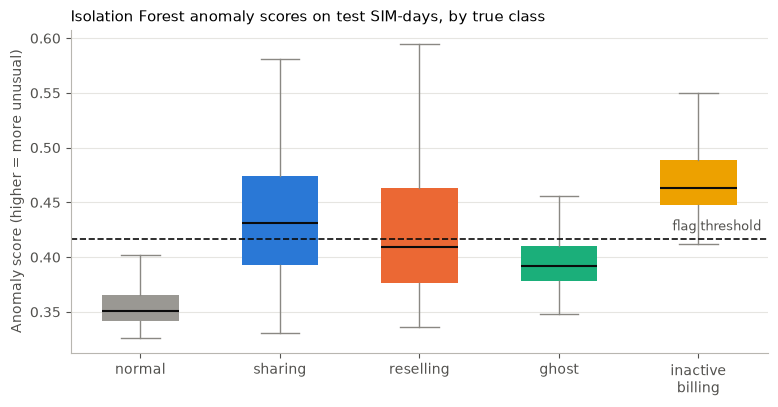

In [24]:
fig, ax = plt.subplots(figsize=(9, 4.2))
data = [iso_score_test[y_test == c] for c in CLASS_ORDER]
bp = ax.boxplot(data, widths=0.55, showfliers=False, patch_artist=True,
                medianprops={"color": "#0b0b0b", "linewidth": 1.5},
                whiskerprops={"color": "#8a8883"}, capprops={"color": "#8a8883"},
                boxprops={"linewidth": 0})
for patch, c in zip(bp["boxes"], CLASS_ORDER):
    patch.set_facecolor(CLASS_COLORS[c])
ax.axhline(iso_threshold, color="#0b0b0b", linewidth=1.2, linestyle="--")
ax.annotate("flag threshold", xy=(len(CLASS_ORDER) + 0.45, iso_threshold), xytext=(0, 4),
            textcoords="offset points", ha="right", va="bottom", fontsize=9, color="#52514e")
ax.set_xticks(range(1, len(CLASS_ORDER) + 1), [SHORT[c] for c in CLASS_ORDER])
ax.set_ylabel("Anomaly score (higher = more unusual)")
ax.set_title("Isolation Forest anomaly scores on test SIM-days, by true class", loc="left")
ax.grid(axis="x", visible=False)
savefig(fig, "iso_scores_by_class.png")
plt.show()

### 5.4 Per SIM: are misuse SIMs caught, and how often do normal SIMs raise false alarms?
An operator reviews SIMs, not single days. A misuse SIM counts as caught if at least one of its misuse days is flagged.

In [25]:
test_frame = pd.DataFrame({"sim": groups[test_idx], "label": y_test, "flag": iso_flag_test})
caught = (test_frame[test_frame.label != "normal"]
          .groupby(["label", "sim"])["flag"].max()
          .groupby("label").agg(["count", "sum"]).reindex(MISUSE))
caught.columns = ["misuse SIMs (test)", "caught (>=1 misuse day flagged)"]
caught["caught (%)"] = (100 * caught.iloc[:, 1] / caught.iloc[:, 0]).round(0)

clean_sims = test_frame.groupby("sim")["label"].apply(lambda s: (s == "normal").all())
clean = test_frame[test_frame.sim.isin(clean_sims[clean_sims].index)]
false_alarm_days = clean.groupby("sim")["flag"].sum()
print(f"{len(false_alarm_days)} test SIMs never misused: "
      f"{(false_alarm_days > 0).mean():.0%} raise at least one false alarm in 90 days; "
      f"median {false_alarm_days.median():.0f} flagged day(s), max {false_alarm_days.max()}")
caught

171 test SIMs never misused: 74% raise at least one false alarm in 90 days; median 1 flagged day(s), max 53


,misuse SIMs (test),caught (>=1 misuse day flagged),caught (%)
label,,,
unauthorized_sharing,32,29,91.0
data_reselling,20,15,75.0
ghost_usage,21,19,90.0
inactive_billing,13,13,100.0


### 5.5 Choosing the alert threshold
The threshold trades missed misuse against false alarms. Flagging a larger share of days catches more misuse but sends operators more false alarms.

In [26]:
rows = []
for share in [0.01, 0.02, 0.055, 0.10, 0.15]:
    thr = np.quantile(iso_score_train, 1 - share)
    flag = (iso_score_test >= thr).astype(int)
    p, r, f, _ = precision_recall_fscore_support(yb_test, flag, average="binary", zero_division=0)
    rows.append({"flag top share of days": f"{share:.1%}", "precision": round(p, 3), "recall": round(r, 3),
                 "f1": round(f, 3), "false alarms per 1,000 normal days": round(1000 * flag[yb_test == 0].mean(), 1)})
pd.DataFrame(rows).set_index("flag top share of days")

,precision,recall,f1,"false alarms per 1,000 normal days"
flag top share of days,,,,
1.0%,0.707,0.128,0.217,2.9
2.0%,0.692,0.240,0.356,5.9
5.5%,0.491,0.504,0.497,29.0
10.0%,0.352,0.650,0.456,66.5
15.0%,0.271,0.771,0.401,114.8


### 5.6 Improving the model: 3-day average + `max_features=0.5`

Sections 5.1–5.5 are the **baseline**. Two changes were chosen by 4-fold cross-validation **within the training
SIMs** (the test set was not used to choose them):

- **3-day average:** each day's score becomes the mean of that SIM's scores today and on the previous 2 days
  (past days only, so it still works live). Misuse lasts days (median 5–11), while normal days have one-off spikes,
  so averaging keeps the first and drops the second. Longer windows were tested: 5 days scored about the same, 7 days
  started to delay alerts (inactive-billing recall fell from 95% to 84%), so 3 days is the balance.
- **`max_features=0.5`:** each tree is trained on a random half of the 48 features. Real misuse is unusual on many
  features at once and still stands out in most trees; a quiet normal day is unusual on only a few volume features,
  so half the trees see nothing odd about it.

Also tested and rejected: using only behaviour features (worse), smaller trees (`max_samples=256`, no gain), and
training on normal days only. The last one made inactive-billing recall collapse (95% to 31%), because the billing
gap is always zero on normal days, so the trees never learn to split on it.

From here on, `iso`, `iso_score_test`, `iso_threshold`, `iso_flag_test` and `iso_metrics` refer to the **improved**
model (used in sections 7 and 8); the baseline is kept as `iso_base` / `base`.

In [27]:
SMOOTH_WINDOW = 3     # days averaged per SIM (today + 2 previous days)
MAX_FEATURES = 0.5    # share of features each tree may use

def smooth_scores(scores, idx, window=SMOOTH_WINDOW):
    """Mean of each SIM's score over today and the previous window-1 days (past days only).
    `idx` = positions of these rows in df, used to look up each row's SIM and date."""
    s = pd.DataFrame({"score": scores, "sim": df["sim_id"].to_numpy()[idx],
                      "date": pd.to_datetime(df["date"]).to_numpy()[idx]})
    s = s.sort_values(["sim", "date"])
    s["smoothed"] = s.groupby("sim")["score"].transform(lambda x: x.rolling(window, min_periods=1).mean())
    return s["smoothed"].sort_index().to_numpy()  # back to the original row order

# Keep the baseline for comparison
iso_base = iso
base = {"flag": iso_flag_test, "score": iso_score_test, "threshold": iso_threshold}

iso = IsolationForest(n_estimators=300, max_samples=4096, contamination=contamination,
                      max_features=MAX_FEATURES, random_state=SEED, n_jobs=-1)
t0 = time.time()
iso.fit(X_train)  # still no labels
print(f"Trained in {time.time() - t0:.1f}s")

iso_score_train = smooth_scores(-iso.score_samples(X_train), train_idx)
iso_score_test = smooth_scores(-iso.score_samples(X_test), test_idx)
iso_threshold = float(np.quantile(iso_score_train, 1 - contamination))
iso_flag_test = (iso_score_test >= iso_threshold).astype(int)
iso_metrics = binary_metrics(yb_test, iso_flag_test, iso_score_test)
print(f"Threshold: {iso_threshold:.4f} -> flags {iso_flag_test.mean():.2%} of test days")

Trained in 4.0s


Threshold: 0.4075 -> flags 5.33% of test days


#### Baseline vs improved (test SIMs)

In [28]:
def iso_summary(flag, score):
    out = dict(binary_metrics(yb_test, flag, score))
    for c in CLASS_ORDER:
        out[f"days flagged: {SHORT[c].replace(chr(10), ' ')}"] = flag[y_test == c].mean()
    out["days flagged: quiet normal (<50 MB)"] = flag[quiet_normal].mean()
    tf = pd.DataFrame({"sim": groups[test_idx], "label": y_test, "flag": flag})
    for c in MISUSE:
        out[f"SIMs caught: {SHORT[c].replace(chr(10), ' ')}"] = tf[tf.label == c].groupby("sim")["flag"].max().mean()
    never = tf[tf.sim.isin(clean_sims[clean_sims].index)]
    out["never-misused SIMs with >=1 false alarm"] = (never.groupby("sim")["flag"].sum() > 0).mean()
    return out

iso_comparison = pd.DataFrame({"baseline": iso_summary(base["flag"], base["score"]),
                               "improved": iso_summary(iso_flag_test, iso_score_test)})
iso_comparison["change"] = iso_comparison["improved"] - iso_comparison["baseline"]
iso_comparison.round(3)

,baseline,improved,change
precision,0.491,0.619,0.128
recall,0.505,0.628,0.124
f1,0.498,0.624,0.126
roc_auc,0.917,0.958,0.041
pr_auc,0.474,0.627,0.153
days flagged: normal,0.029,0.021,-0.008
days flagged: sharing,0.592,0.710,0.118
days flagged: reselling,0.432,0.616,0.184
days flagged: ghost,0.176,0.361,0.185
days flagged: inactive billing,0.994,0.948,-0.046


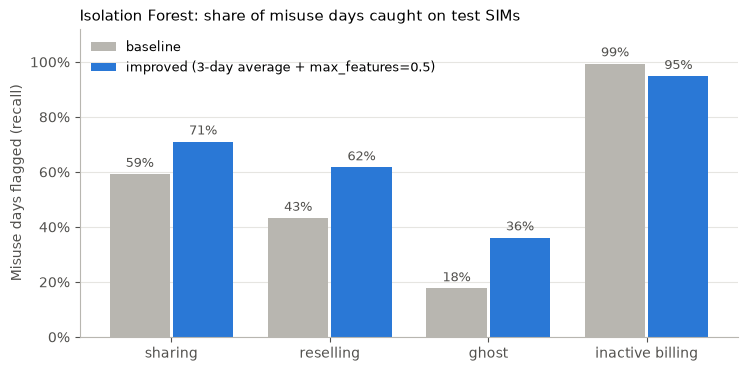

In [29]:
# Share of each misuse type's test days flagged, before and after
from matplotlib.ticker import PercentFormatter

rec_base = [base["flag"][y_test == c].mean() for c in MISUSE]
rec_new = [iso_flag_test[y_test == c].mean() for c in MISUSE]
labels = [SHORT[c].replace("\n", " ") for c in MISUSE]
xpos = np.arange(len(MISUSE))
w = 0.38

fig, ax = plt.subplots(figsize=(8.5, 4))
b1 = ax.bar(xpos - w / 2 - 0.01, rec_base, w, color="#b8b6b0", label="baseline")
b2 = ax.bar(xpos + w / 2 + 0.01, rec_new, w, color="#2a78d6", label="improved (3-day average + max_features=0.5)")
for bars in (b1, b2):
    ax.bar_label(bars, labels=[f"{v:.0%}" for v in bars.datavalues], padding=3, fontsize=9, color="#52514e")
ax.set_xticks(xpos, labels)
ax.set_ylim(0, 1.12)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_ylabel("Misuse days flagged (recall)")
ax.set_title("Isolation Forest: share of misuse days caught on test SIMs", loc="left")
ax.grid(axis="x", visible=False)
ax.legend(frameon=False, loc="upper left", fontsize=9)
savefig(fig, "iso_baseline_vs_improved.png")
plt.show()

#### Threshold trade-off for the improved model

In [30]:
rows = []
for share in [0.01, 0.02, 0.055, 0.10, 0.15]:
    thr = np.quantile(iso_score_train, 1 - share)
    flag = (iso_score_test >= thr).astype(int)
    p, r, f, _ = precision_recall_fscore_support(yb_test, flag, average="binary", zero_division=0)
    rows.append({"flag top share of days": f"{share:.1%}", "precision": round(p, 3), "recall": round(r, 3),
                 "f1": round(f, 3), "false alarms per 1,000 normal days": round(1000 * flag[yb_test == 0].mean(), 1)})
pd.DataFrame(rows).set_index("flag top share of days")

,precision,recall,f1,"false alarms per 1,000 normal days"
flag top share of days,,,,
1.0%,0.785,0.157,0.261,2.4
2.0%,0.782,0.287,0.420,4.4
5.5%,0.619,0.628,0.623,21.4
10.0%,0.441,0.822,0.574,57.7
15.0%,0.318,0.902,0.470,107.2


### 5.7 Findings

**The improved model is better on almost every measure** (251 test SIMs; the changes were chosen on training SIMs only, and the test results confirm the cross-validation estimate):

| Measure | Baseline | Improved |
|---|---|---|
| Precision | 0.49 | **0.62** |
| Recall | 0.50 | **0.63** |
| F1 | 0.50 | **0.62** |
| ROC-AUC | 0.917 | **0.958** |
| PR-AUC | 0.474 | **0.627** |
| Normal days flagged (false alarms) | 2.9% | **2.1%** |
| Quiet normal days (<50 MB) flagged | 9.6% | **5.3%** |
| Never-misused SIMs with at least one false alarm in 90 days | 74% | **26%** |

Precision and recall both rose by about 12 points at the same time, which moving the threshold alone cannot do. The biggest operational gain is in false alarms: only about one in four clean SIMs now raises any alert over three months, instead of three in four.

**By misuse type** (share of days caught): sharing 59% → 71%, reselling 43% → 62%, ghost usage 18% → 36%, inactive billing 99% → 95%. Ghost usage doubled but is still the weakest type for this model.

**The trade-off: very short episodes.** Averaging over 3 days dilutes episodes that last only a day or two. Three sharing SIMs caught by the baseline are now missed, and their episodes lasted 1, 2 and 2 days (the median sharing episode lasts 10). One reselling SIM with a 4-day episode is also missed. Inactive billing slips slightly for the same reason: its first day is averaged with two normal days. This is acceptable for an operator-facing alert, where a one-day blip is usually not worth an investigation, but it should be stated in the write-up.

**Threshold:** flagging the top 2% of days now gives 78% precision (up from 69%) and catches 29% of misuse days; flagging 10% catches 82% at 44% precision.

**For deployment (section 8):** the service must apply the same 3-day average, so `SMOOTH_WINDOW = 3` is saved with the model, and scoring a SIM needs its scores for the 2 previous days as well as today.

**For the write-up:** the improvement comes from treating misuse as something that persists over days rather than judging each day alone, and from making each tree look at a random half of the features so that days unusual on only a few features (such as a SIM owner on leave) stand out less. Training on normal days only, a common anomaly-detection approach, was tested and rejected: it cut inactive-billing recall from 95% to 31%, because the billing gap never varies on normal days, so the trees never learn to use it.


## 6. Random Forest  (issue #6)

- [ ] Multiclass, `class_weight='balanced_subsample'`, 300-400 trees, `n_jobs=-1`
- [ ] Optional: tune `max_depth` / `min_samples_leaf` with `GroupKFold` on the training SIMs
- [ ] Classification report per class + confusion matrix (save to `REPORTS_DIR`)

## 7. Compare models  (issue #7)

- [ ] Comparison table: Isolation Forest vs Random Forest
- [ ] Precision-recall curves and feature importance chart (save to `REPORTS_DIR`)
- [ ] Notes for the write-up: inactive-billing separability, data-reselling weakness

## 8. Save models and metadata  (issue #8)

- [ ] Refit both models on ALL SIMs; save with `joblib` to `MODELS_DIR`
- [ ] Save metadata JSON: feature list in order, Isolation Forest threshold, class names, sklearn version
- [ ] Save metrics JSON to `REPORTS_DIR`